<a href="https://colab.research.google.com/github/Barathraj009/world-energy-consumption-forecasting/blob/main/World_Energy_Consumption_Forecastin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from google.colab import files

print("TensorFlow version:", tf.__version__)

# Trigger file upload widget
print("Please upload the 'World Energy Consumption.csv' file below:")
uploaded = files.upload()
filename = list(uploaded.keys())[0]
print(f"Successfully uploaded: {filename}")


TensorFlow version: 2.21.0
Please upload the 'World Energy Consumption.csv' file below:


Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023 (4).csv
Successfully uploaded: World_Energy_By_Country_And_Region_1965_to_2023 (4).csv


In [13]:
# Load the dataset
df = pd.read_csv(filename)

# The dataset is in wide format: 'Country' column followed by year columns ('1965', '1966', etc.)
# Identify country column (handles case variants like 'Country' or 'country')
country_col = next((col for col in df.columns if col.lower() == 'country'), None)
if not country_col:
    raise ValueError(f"Could not find country column. Columns: {list(df.columns)[:5]}")

# Reshape the table from wide format to long format
year_cols = [col for col in df.columns if col.isdigit()]
if not year_cols:
    raise ValueError("No year columns found in the dataset.")

# Melt wide format to long format
df_long = df.melt(
    id_vars=[country_col],
    value_vars=year_cols,
    var_name='year',
    value_name='energy_consumption'
)

# Standardize column names
df_long = df_long.rename(columns={country_col: 'country'})
df_long['year'] = pd.to_numeric(df_long['year'])
df_long['energy_consumption'] = pd.to_numeric(df_long['energy_consumption'], errors='coerce')

# Fill target column reference
energy_col = 'energy_consumption'

# Find countries with at least 20 valid records
country_counts = df_long.dropna(subset=[energy_col]).groupby('country')['year'].count()
valid_countries = country_counts[country_counts >= 20].index.tolist()

print("Sample of available countries with >20 years of data:")
print(valid_countries[:15])

# --- CONFIGURATION: SELECT YOUR TARGET COUNTRY HERE ---
# Standardize: In this CSV, 'United States' is represented as 'US'
TARGET_COUNTRY = "US"
# ------------------------------------------------------

if TARGET_COUNTRY not in df_long['country'].unique():
    raise ValueError(f"Country '{TARGET_COUNTRY}' not found in the dataset. Available: {valid_countries[:15]}")

# Filter, clean missing values, sort chronologically
country_df = df_long[df_long['country'] == TARGET_COUNTRY].copy()
country_df = country_df.dropna(subset=[energy_col])
country_df = country_df.sort_values(by='year').reset_index(drop=True)

print(f"\nFiltered dataset for {TARGET_COUNTRY}: Found {len(country_df)} records from {country_df['year'].min()} to {country_df['year'].max()}.")


Sample of available countries with >20 years of data:
['                 European Union #', '                 Non-OECD', 'Algeria', 'Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bangladesh', 'Belarus', 'Belgium', 'Brazil', 'Bulgaria', 'Canada', 'Central America', 'Chile']

Filtered dataset for US: Found 59 records from 1965 to 2023.


In [14]:
# Extract target array series
years = country_df['year'].values
energy_data = country_df[[energy_col]].values.astype('float32')

# Chronological split to avoid data leakage (80% train, 20% test)
split_idx = int(len(energy_data) * 0.8)
train_data = energy_data[:split_idx]
test_data = energy_data[split_idx:]

# Fit MinMaxScaler using training data boundaries only
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)

# Window compilation function (5-year window -> 6th-year target)
def create_dataset(dataset, lookback=5):
    X, Y = [], []
    for i in range(len(dataset) - lookback):
        X.append(dataset[i:(i + lookback), 0])
        Y.append(dataset[i + lookback, 0])
    return np.array(X), np.array(Y)

LOOKBACK = 5
X_train, y_train = create_dataset(train_scaled, LOOKBACK)
X_test, y_test = create_dataset(test_scaled, LOOKBACK)

# Reshape arrays to fit standard LSTM tensor entry parameters [Samples, Time Steps, Features]
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

print(f"Training set dimensions: X={X_train.shape}, y={y_train.shape}")
print(f"Testing set dimensions: X={X_test.shape}, y={y_test.shape}")


Training set dimensions: X=(42, 5, 1), y=(42,)
Testing set dimensions: X=(7, 5, 1), y=(7,)


In [18]:
# Build recurrent neural network topology
model = Sequential([
    tf.keras.layers.Input(shape=(LOOKBACK, 1)),
    LSTM(64, activation='relu', return_sequences=True),
    Dropout(0.1),
    LSTM(32, activation='relu'),
    Dropout(0.1),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# Train model sequence
print("\nTraining LSTM network...")
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=4,
    validation_data=(X_test, y_test),
    verbose=1
)
print("Model training completed successfully.")


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 5, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 5, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)


Training LSTM network...
Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.4788 - val_loss: 0.7592
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4135 - val_loss: 0.6233
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.3048 - val_loss: 0.3941
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1472 - val_loss: 0.0467
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0297 - val_loss: 0.0276
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0170 - val_loss: 0.0243
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0272 - val_loss: 0.0036
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0115 - val_loss: 0.0050
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0190 - val_loss: 0.0060
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0156 - val_loss: 0.0042
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0146 - val_loss: 0.0057
Epoch 12/100
11/11 ━━━━━━━━

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step

--- EVALUATION METRICS (US) ---
LSTM Model         -> MAE: 2.1424 | RMSE: 3.2052
Persistence Model  -> MAE: 2.7714 | RMSE: 3.5853
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step

🔮 Out-of-Sample Forecast for Year 2024: 95.8640


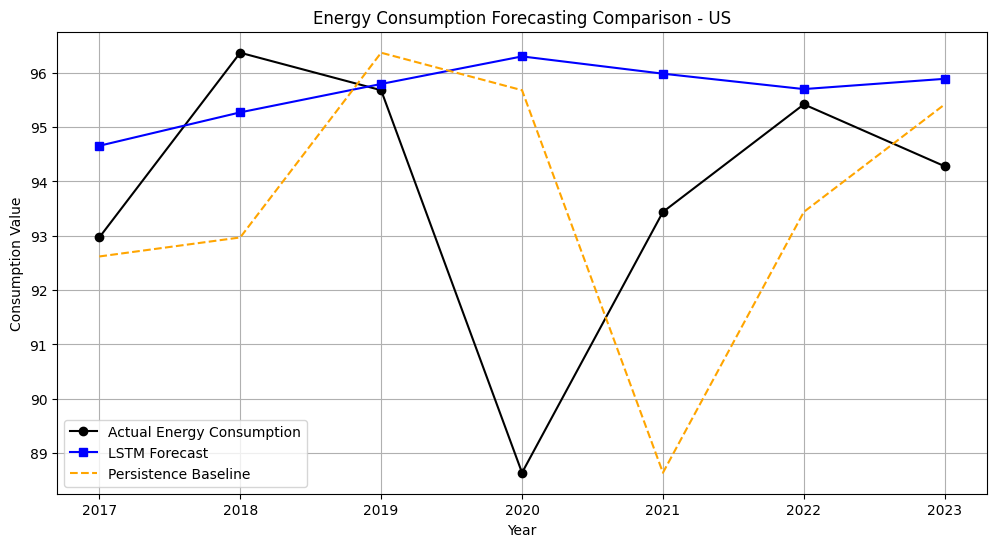


💾 Files saved: 'lstm_energy_model.keras', 'forecasting_results.csv', and 'energy_forecast_plot.png'.

🧠 INTERACTIVE FORECASTER: ENTER 5 YEARS OF CUSTOM ENERGY DATA
Historical range context for scale reference: Min=51.98, Max=97.44

Enter 5 sequential values separated by commas (e.g., 90,92,95,91,96): 94.1, 95.3, 92.8, 94.0, 95.1

✅ Input Sequence Accepted: [94.1, 95.3, 92.8, 94.0, 95.1]
🔮 Predicted Value for Year 6: 96.5680


In [20]:
# Generate predictions and map back to true domain scale
lstm_predictions_scaled = model.predict(X_test)
lstm_predictions = scaler.inverse_transform(lstm_predictions_scaled)
actual_y_test = scaler.inverse_transform(y_test.reshape(-1, 1))

# Extract persistence baseline directly from the last window index step (t-1 value)
persistence_predictions = scaler.inverse_transform(X_test[:, -1, :])

# Calculate performance metrics
mae_lstm = mean_absolute_error(actual_y_test, lstm_predictions)
rmse_lstm = np.sqrt(mean_squared_error(actual_y_test, lstm_predictions))

mae_base = mean_absolute_error(actual_y_test, persistence_predictions)
rmse_base = np.sqrt(mean_squared_error(actual_y_test, persistence_predictions))

print(f"\n--- EVALUATION METRICS ({TARGET_COUNTRY}) ---")
print(f"LSTM Model         -> MAE: {mae_lstm:.4f} | RMSE: {rmse_lstm:.4f}")
print(f"Persistence Model  -> MAE: {mae_base:.4f} | RMSE: {rmse_base:.4f}")

# Forecast the next out-of-sample year using the latest 5 years
latest_5_years_scaled = test_scaled[-LOOKBACK:].reshape(1, LOOKBACK, 1)
next_year_scaled = model.predict(latest_5_years_scaled)
next_year_forecast = scaler.inverse_transform(next_year_scaled)
next_year_label = int(years[-1] + 1)

# FIXED: Added .item() to extract the scalar float from the numpy array
print(f"\n🔮 Out-of-Sample Forecast for Year {next_year_label}: {next_year_forecast.item():.4f}")

# Plot actual vs predicted values
test_years = years[split_idx + LOOKBACK:]
plt.figure(figsize=(12, 6))
plt.plot(test_years, actual_y_test, marker='o', label='Actual Energy Consumption', color='black')
plt.plot(test_years, lstm_predictions, marker='s', label='LSTM Forecast', color='blue')
plt.plot(test_years, persistence_predictions, linestyle='--', label='Persistence Baseline', color='orange')
plt.title(f'Energy Consumption Forecasting Comparison - {TARGET_COUNTRY}')
plt.xlabel('Year')
plt.ylabel('Consumption Value')
plt.legend()
plt.grid(True)
plt.savefig('energy_forecast_plot.png')
plt.show()

# Save outputs using the modern native Keras format to prevent warnings
model.save('lstm_energy_model.keras')

results_df = pd.DataFrame({
    'Year': test_years, 'Actual': actual_y_test.flatten(),
    'LSTM_Predicted': lstm_predictions.flatten(), 'Baseline_Predicted': persistence_predictions.flatten()
})
results_df.to_csv('forecasting_results.csv', index=False)
print("\n💾 Files saved: 'lstm_energy_model.keras', 'forecasting_results.csv', and 'energy_forecast_plot.png'.")

# -------------------------------------------------------------------------
# INTERACTIVE MANUAL INPUT INTERFACE
# -------------------------------------------------------------------------
print("\n" + "="*60)
print("🧠 INTERACTIVE FORECASTER: ENTER 5 YEARS OF CUSTOM ENERGY DATA")
print("="*60)
print(f"Historical range context for scale reference: Min={train_data.min():.2f}, Max={train_data.max():.2f}")

try:
    # Accept user entries as standard comma-separated sequences
    user_input_str = input("\nEnter 5 sequential values separated by commas (e.g., 90,92,95,91,96): ")
    raw_inputs = [float(x.strip()) for x in user_input_str.split(',')]

    if len(raw_inputs) != 5:
        print(f"❌ Error: Expected exactly 5 values, but received {len(raw_inputs)}.")
    else:
        # Scale inputs using our locked boundaries to prevent target shift distortion
        custom_sequence = np.array(raw_inputs).reshape(-1, 1)
        custom_scaled = scaler.transform(custom_sequence)
        custom_tensor = custom_scaled.reshape(1, LOOKBACK, 1)

        # Predict the 6th year outcome
        predicted_scaled = model.predict(custom_tensor, verbose=0)
        predicted_final = scaler.inverse_transform(predicted_scaled)

        print(f"\n✅ Input Sequence Accepted: {raw_inputs}")
        # FIXED: Added .item() here as well to cleanly format manual inputs
        print(f"🔮 Predicted Value for Year 6: {predicted_final.item():.4f}")
except Exception as e:
    print(f"❌ Invalid entry format. Technical details: {e}")
